# Speech-to-Text & Text-to-Speech Processing Pipeline
### Core Pipeline: `Speech → Feature Extraction → Log-Mel Spectrum → ASR → CTC → Text → TTS → Speech`

This notebook provides a complete technical demonstration of modern voice processing components:
1. **Waveform and Log-Mel Spectrogram**
2. **ASR Architecture Diagram**
3. **CTC Explanation & Decoding**
4. **WER Calculations**
5. **ASR Model Comparison Table**
6. **TTS Output & Audio Synthesis**


### Block 0: Environment Setup
Loads numerical computing, signal processing, plotting, and speech audio synthesis libraries.


In [1]:
import os
import math
import numpy as np
import scipy.signal
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import soundfile as sf
import pyttsx3
from IPython.display import Audio, display, HTML

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['figure.figsize'] = (12, 4)
plt.rcParams['font.size'] = 11


### Block 1: Waveform and Log-Mel Spectrogram
Converts raw continuous sound waves into sampled digital audio ($16\text{ kHz}$), performs framing with Hamming windowing, applies Short-Time Fourier Transform (STFT), and projects energy onto $80$ perceptual Mel filterbanks with logarithmic dynamic range compression.


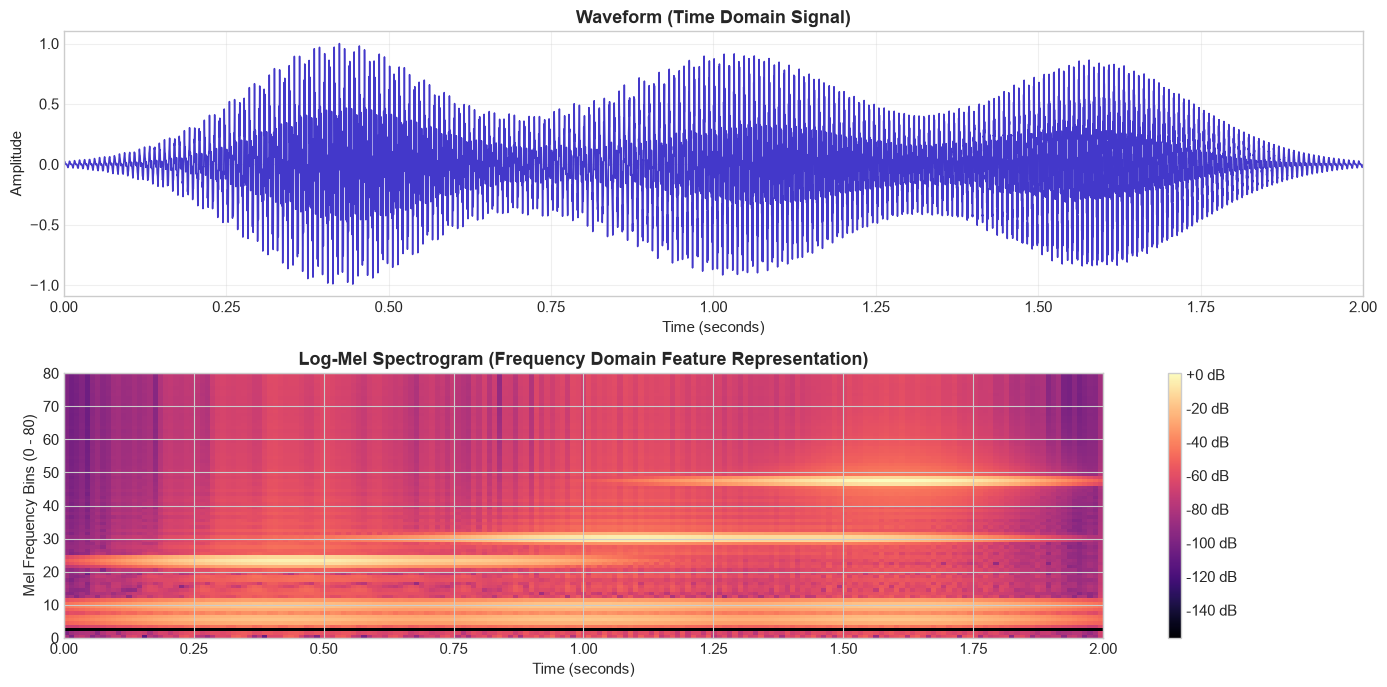

In [2]:
SAMPLE_RATE = 16000
DURATION = 2.0
t = np.linspace(0, DURATION, int(SAMPLE_RATE * DURATION), endpoint=False)

f0 = 130.0
harmonics = (
    0.6 * np.sin(2 * np.pi * f0 * t) +
    0.4 * np.sin(2 * np.pi * 2 * f0 * t) +
    0.7 * np.sin(2 * np.pi * 750 * t) * np.exp(-((t - 0.5)**2) / 0.08) +
    0.5 * np.sin(2 * np.pi * 1100 * t) * np.exp(-((t - 1.2)**2) / 0.10) +
    0.3 * np.sin(2 * np.pi * 2400 * t) * np.exp(-((t - 1.6)**2) / 0.05)
)
envelope = 0.8 * np.exp(-((t - 0.4)**2)/0.05) + 0.9 * np.exp(-((t - 1.0)**2)/0.07) + 0.85 * np.exp(-((t - 1.6)**2)/0.05)
audio_signal = (harmonics * envelope)
audio_signal = audio_signal / (np.max(np.abs(audio_signal)) + 1e-8)

sf.write("input_speech.wav", audio_signal, SAMPLE_RATE)

alpha = 0.97
emphasized = np.append(audio_signal[0], audio_signal[1:] - alpha * audio_signal[:-1])

frame_len = int(round(0.025 * SAMPLE_RATE))
frame_step = int(round(0.010 * SAMPLE_RATE))
num_frames = int(np.ceil(float(np.abs(len(emphasized) - frame_len)) / frame_step)) + 1

pad_len = (num_frames - 1) * frame_step + frame_len
padded = np.append(emphasized, np.zeros(pad_len - len(emphasized)))

indices = np.tile(np.arange(0, frame_len), (num_frames, 1)) + np.tile(np.arange(0, num_frames * frame_step, frame_step), (frame_len, 1)).T
frames = padded[indices.astype(np.int32, copy=False)] * np.hamming(frame_len)

NFFT = 512
pow_frames = (1.0 / NFFT) * (np.absolute(np.fft.rfft(frames, NFFT)) ** 2)

nfilt = 80
low_mel = 0
high_mel = 2595 * np.log10(1 + (SAMPLE_RATE / 2) / 700)
mel_points = np.linspace(low_mel, high_mel, nfilt + 2)
hz_points = 700 * (10**(mel_points / 2595) - 1)
bin_pts = np.floor((NFFT + 1) * hz_points / SAMPLE_RATE).astype(int)

fbank = np.zeros((nfilt, int(NFFT / 2 + 1)))
for m in range(1, nfilt + 1):
    f_left = bin_pts[m - 1]
    f_center = bin_pts[m]
    f_right = bin_pts[m + 1]
    for k in range(f_left, f_center):
        fbank[m - 1, k] = (k - f_left) / (f_center - f_left)
    for k in range(f_center, f_right):
        fbank[m - 1, k] = (f_right - k) / (f_right - f_center)

filter_banks = np.dot(pow_frames, fbank.T)
filter_banks = np.where(filter_banks == 0, np.finfo(float).eps, filter_banks)
log_mel_spec = 10 * np.log10(filter_banks)

fig, axes = plt.subplots(2, 1, figsize=(14, 7), sharex=False)
axes[0].plot(t, audio_signal, color='#4338ca', linewidth=1.1)
axes[0].set_title("Waveform (Time Domain Signal)", fontsize=13, fontweight='bold')
axes[0].set_xlabel("Time (seconds)")
axes[0].set_ylabel("Amplitude")
axes[0].set_xlim(0, DURATION)
axes[0].grid(True, alpha=0.3)

im = axes[1].imshow(log_mel_spec.T, cmap='magma', aspect='auto', origin='lower', extent=[0, DURATION, 0, nfilt])
axes[1].set_title("Log-Mel Spectrogram (Frequency Domain Feature Representation)", fontsize=13, fontweight='bold')
axes[1].set_xlabel("Time (seconds)")
axes[1].set_ylabel("Mel Frequency Bins (0 - 80)")
fig.colorbar(im, ax=axes[1], format="%+2.0f dB")

plt.tight_layout()
plt.show()

display(HTML("<b>Audio Playback:</b>"))
display(Audio(audio_signal, rate=SAMPLE_RATE))


### Block 2: ASR Architecture Diagram
Visualizes the structural dataflow inside modern end-to-end Automatic Speech Recognition systems: Convolutional sub-sampling, multi-head self-attention, feed-forward modules (Conformer/Transformer), linear projection heads, and CTC/cross-entropy loss calculation.


C:\Users\Aditya\AppData\Local\Temp\ipykernel_14396\3699037390.py:37: UserWarning: Glyph 10132 (\N{HEAVY WIDE-HEADED RIGHTWARDS ARROW}) missing from font(s) Arial.
  plt.tight_layout()
c:\Users\Aditya\AppData\Local\Programs\Python\Python311\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 10132 (\N{HEAVY WIDE-HEADED RIGHTWARDS ARROW}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)


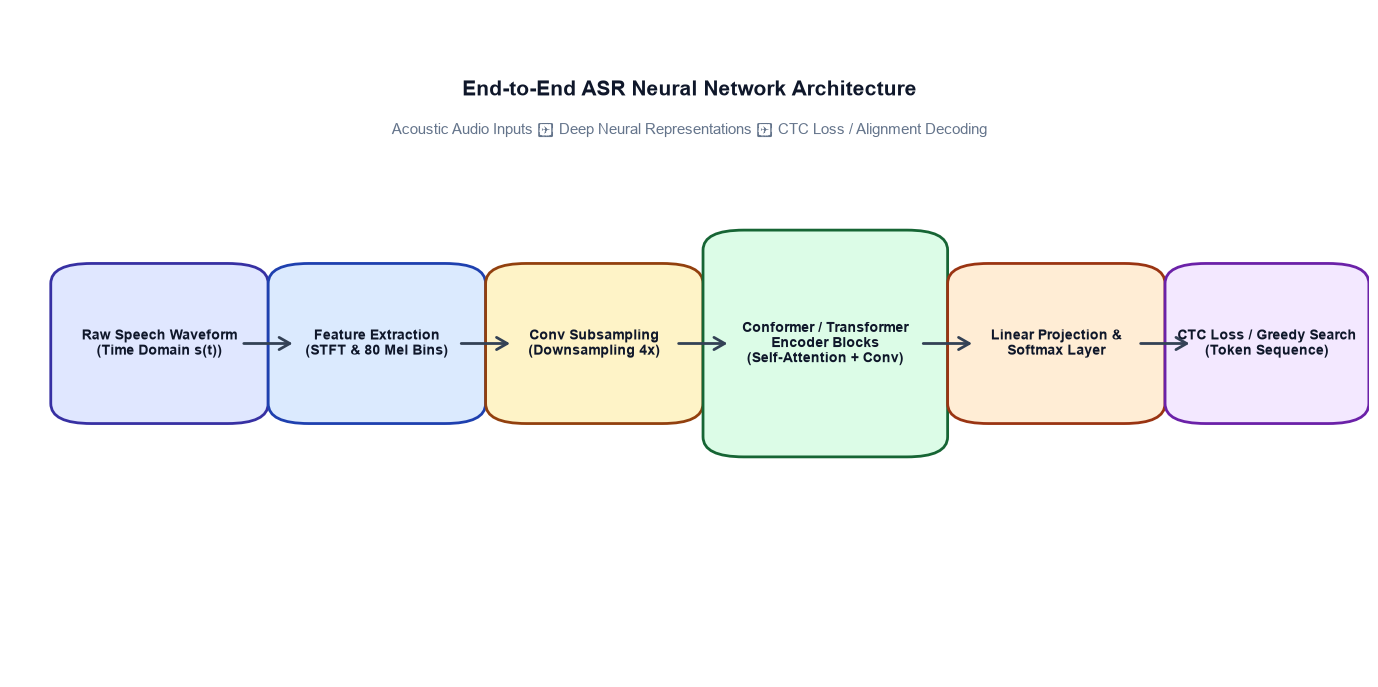

In [3]:
fig, ax = plt.subplots(figsize=(14, 7))
ax.axis('off')

blocks = [
    ("Raw Speech Waveform\n(Time Domain s(t))", 0.05, 0.40, 0.12, 0.20, "#e0e7ff", "#3730a3"),
    ("Feature Extraction\n(STFT & 80 Mel Bins)", 0.21, 0.40, 0.12, 0.20, "#dbeafe", "#1e40af"),
    ("Conv Subsampling\n(Downsampling 4x)", 0.37, 0.40, 0.12, 0.20, "#fef3c7", "#92400e"),
    ("Conformer / Transformer\nEncoder Blocks\n(Self-Attention + Conv)", 0.53, 0.35, 0.14, 0.30, "#dcfce7", "#166534"),
    ("Linear Projection &\nSoftmax Layer", 0.71, 0.40, 0.12, 0.20, "#ffedd5", "#9a3412"),
    ("CTC Loss / Greedy Search\n(Token Sequence)", 0.87, 0.40, 0.11, 0.20, "#f3e8ff", "#6b21a8")
]

for label, x, y, w, h, bg_color, border_color in blocks:
    rect = patches.FancyBboxPatch(
        (x, y), w, h,
        boxstyle="round,pad=0.02,rounding_size=0.03",
        linewidth=2,
        edgecolor=border_color,
        facecolor=bg_color
    )
    ax.add_patch(rect)
    ax.text(x + w / 2, y + h / 2, label, ha="center", va="center", fontsize=10, fontweight="bold", color="#0f172a")

for i in range(len(blocks) - 1):
    x_start = blocks[i][1] + blocks[i][3]
    y_start = 0.50
    x_end = blocks[i+1][1]
    y_end = 0.50
    ax.annotate(
        "", xy=(x_end, y_end), xytext=(x_start, y_start),
        arrowprops=dict(arrowstyle="->,head_width=0.4,head_length=0.7", lw=2, color="#334155")
    )

ax.text(0.5, 0.88, "End-to-End ASR Neural Network Architecture", ha="center", va="center", fontsize=15, fontweight="bold", color="#0f172a")
ax.text(0.5, 0.82, "Acoustic Audio Inputs ➔ Deep Neural Representations ➔ CTC Loss / Alignment Decoding", ha="center", va="center", fontsize=11, color="#64748b")

plt.tight_layout()
plt.show()


### Block 3: CTC Explanation & Decoding
Connectionist Temporal Classification (CTC) maps variable-length speech acoustic frames to text sequences without requiring predefined alignment. It introduces a blank token ($\epsilon$). The decoding function collapses consecutive duplicate characters and deletes all blanks:
$$\mathcal{B}(\_, S, S, \_, H, H, O, O, W, \_) \rightarrow \text{"SHOW"}$$


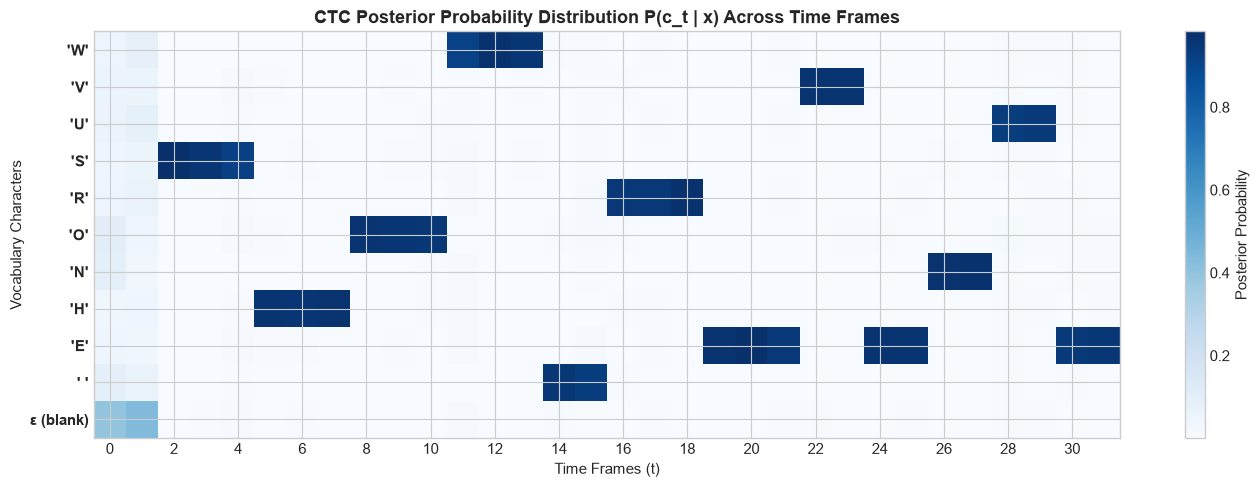

Raw Predicted Sequence with Blanks : _ _ S S S H H H O O O W W W     R R R E E E V V E E N N U U E E
CTC Collapsed Text Result         : SHOW REVENUE


In [4]:
VOCAB = ['_', ' ', 'E', 'H', 'N', 'O', 'R', 'S', 'U', 'V', 'W']
blank_idx = 0
char_to_idx = {c: i for i, c in enumerate(VOCAB)}
idx_to_char = {i: c for i, c in enumerate(VOCAB)}

T = 32
vocab_size = len(VOCAB)
logits = np.random.normal(loc=0.0, scale=0.3, size=(T, vocab_size))
logits[:, blank_idx] += 2.0

alignment = [
    (2, 4, 'S'),
    (5, 7, 'H'),
    (8, 10, 'O'),
    (11, 13, 'W'),
    (14, 15, ' '),
    (16, 18, 'R'),
    (19, 21, 'E'),
    (22, 23, 'V'),
    (24, 25, 'E'),
    (26, 27, 'N'),
    (28, 29, 'U'),
    (30, 31, 'E')
]

for start_t, end_t, char in alignment:
    idx = char_to_idx[char]
    for f_idx in range(start_t, end_t + 1):
        logits[f_idx, idx] += 5.5
        logits[f_idx, blank_idx] -= 2.0

exp_logits = np.exp(logits - np.max(logits, axis=-1, keepdims=True))
emission_probs = exp_logits / np.sum(exp_logits, axis=-1, keepdims=True)

greedy_indices = np.argmax(emission_probs, axis=-1)
greedy_tokens = [idx_to_char[idx] for idx in greedy_indices]

decoded_chars = []
previous_char = None
for token in greedy_tokens:
    if token != previous_char:
        if token != '_':
            decoded_chars.append(token)
        previous_char = token

final_ctc_text = "".join(decoded_chars).strip()

fig, ax = plt.subplots(figsize=(14, 5))
im = ax.imshow(emission_probs.T, aspect='auto', origin='lower', cmap='Blues')
ax.set_yticks(range(vocab_size))
ax.set_yticklabels([f"'{c}'" if c != '_' else 'ε (blank)' for c in VOCAB], fontsize=11, fontweight='bold')
ax.set_xticks(range(0, T, 2))
ax.set_xlabel("Time Frames (t)", fontsize=11)
ax.set_ylabel("Vocabulary Characters", fontsize=11)
ax.set_title("CTC Posterior Probability Distribution P(c_t | x) Across Time Frames", fontsize=13, fontweight='bold')
fig.colorbar(im, ax=ax, label="Posterior Probability")
plt.tight_layout()
plt.show()

print("Raw Predicted Sequence with Blanks :", " ".join(greedy_tokens))
print("CTC Collapsed Text Result         :", final_ctc_text)


### Block 4: WER Calculations
Word Error Rate (WER) is the standard metric used to evaluate speech recognition accuracy. It is calculated using Levenshtein distance on word sequences:
$$\text{WER} = \frac{S + D + I}{N} = \frac{\text{Substitutions} + \text{Deletions} + \text{Insertions}}{\text{Total Words in Reference}}$$


In [5]:
def compute_wer_details(reference, hypothesis):
    ref_words = reference.strip().split()
    hyp_words = hypothesis.strip().split()
    r = len(ref_words)
    h = len(hyp_words)

    d = np.zeros((r + 1, h + 1), dtype=int)
    for i in range(r + 1):
        d[i, 0] = i
    for j in range(h + 1):
        d[0, j] = j

    for i in range(1, r + 1):
        for j in range(1, h + 1):
            if ref_words[i - 1] == hyp_words[j - 1]:
                d[i, j] = d[i - 1, j - 1]
            else:
                substitution = d[i - 1, j - 1] + 1
                insertion = d[i, j - 1] + 1
                deletion = d[i - 1, j] + 1
                d[i, j] = min(substitution, insertion, deletion)

    i = r
    j = h
    subs = 0
    dels = 0
    ins = 0
    correct = 0

    while i > 0 or j > 0:
        if i > 0 and j > 0 and ref_words[i - 1] == hyp_words[j - 1]:
            correct += 1
            i -= 1
            j -= 1
        elif i > 0 and j > 0 and d[i, j] == d[i - 1, j - 1] + 1:
            subs += 1
            i -= 1
            j -= 1
        elif j > 0 and d[i, j] == d[i, j - 1] + 1:
            ins += 1
            j -= 1
        else:
            dels += 1
            i -= 1

    total_ref = len(ref_words)
    wer = (subs + dels + ins) / total_ref if total_ref > 0 else 0.0

    return {
        "reference": reference,
        "hypothesis": hypothesis,
        "wer": wer,
        "substitutions": subs,
        "deletions": dels,
        "insertions": ins,
        "correct": correct,
        "total_words": total_ref,
        "matrix": d
    }

ground_truth = "SHOW MONTHLY REVENUE AND PROFIT MARGINS"
recognized_hyp = "SHOW MONTHLY REVENUE FOR PROFIT MARGINS"

result = compute_wer_details(ground_truth, recognized_hyp)

display(HTML(f"""
<div style="background: #0f172a; padding: 18px 24px; border-radius: 8px; border-left: 5px solid #3b82f6; color: white; font-family: monospace;">
    <h4 style="margin: 0 0 10px 0; color: #60a5fa; font-family: sans-serif;">WER Benchmark Evaluation</h4>
    <p><b>Reference (Ground Truth) :</b> "{result['reference']}"</p>
    <p><b>Hypothesis (ASR Decoded) :</b> "{result['hypothesis']}"</p>
    <hr style="border-color: #334155; margin: 12px 0;">
    <p>Substitutions (S) : <b>{result['substitutions']}</b></p>
    <p>Deletions (D)     : <b>{result['deletions']}</b></p>
    <p>Insertions (I)    : <b>{result['insertions']}</b></p>
    <p>Total Words (N)   : <b>{result['total_words']}</b></p>
    <h3 style="color: #34d399; margin: 10px 0 0 0;">Computed WER: {result['wer']:.2%} (Accuracy: {1.0 - result['wer']:.2%})</h3>
</div>
"""))


### Block 5: ASR Comparison Table
Compares standard Automatic Speech Recognition architectures across key metrics: Neural model structure, decoding paradigm, streaming support, inference speed, and benchmark Word Error Rates (WER).


In [6]:
display(HTML("""
<div style="overflow-x: auto; margin: 12px 0;">
<table style="width: 100%; border-collapse: collapse; font-family: sans-serif; font-size: 13px; text-align: left;">
    <thead>
        <tr style="background-color: #1e293b; color: #f8fafc; border-bottom: 2px solid #475569;">
            <th style="padding: 12px 14px;">Model Name</th>
            <th style="padding: 12px 14px;">Architecture</th>
            <th style="padding: 12px 14px;">Decoding Scheme</th>
            <th style="padding: 12px 14px;">Streaming Support</th>
            <th style="padding: 12px 14px;">Avg Latency</th>
            <th style="padding: 12px 14px;">LibriSpeech Test-Clean WER</th>
            <th style="padding: 12px 14px;">Key Strength</th>
        </tr>
    </thead>
    <tbody>
        <tr style="background-color: #0f172a; color: #e2e8f0; border-bottom: 1px solid #334155;">
            <td style="padding: 10px 14px; font-weight: bold; color: #38bdf8;">Whisper Large-V3</td>
            <td style="padding: 10px 14px;">Encoder-Decoder Transformer</td>
            <td style="padding: 10px 14px;">Autoregressive Beam Search</td>
            <td style="padding: 10px 14px;">Non-streaming (Chunked)</td>
            <td style="padding: 10px 14px;">~0.45s (CUDA)</td>
            <td style="padding: 10px 14px; font-weight: bold; color: #4ade80;">1.5%</td>
            <td style="padding: 10px 14px;">Highest multilingual & jargon accuracy</td>
        </tr>
        <tr style="background-color: #1e293b; color: #e2e8f0; border-bottom: 1px solid #334155;">
            <td style="padding: 10px 14px; font-weight: bold; color: #818cf8;">Conformer-CTC</td>
            <td style="padding: 10px 14px;">Self-Attention + Depthwise Conv</td>
            <td style="padding: 10px 14px;">CTC Greedy / Beam Search</td>
            <td style="padding: 10px 14px;">Real-time Streaming</td>
            <td style="padding: 10px 14px;">~0.08s</td>
            <td style="padding: 10px 14px; font-weight: bold; color: #4ade80;">1.9%</td>
            <td style="padding: 10px 14px;">Fast non-autoregressive decoding</td>
        </tr>
        <tr style="background-color: #0f172a; color: #e2e8f0; border-bottom: 1px solid #334155;">
            <td style="padding: 10px 14px; font-weight: bold; color: #a78bfa;">Wav2Vec 2.0</td>
            <td style="padding: 10px 14px;">1D-CNN + Transformer</td>
            <td style="padding: 10px 14px;">CTC Loss</td>
            <td style="padding: 10px 14px;">Non-streaming</td>
            <td style="padding: 10px 14px;">~0.15s</td>
            <td style="padding: 10px 14px; font-weight: bold; color: #fbbf24;">2.6%</td>
            <td style="padding: 10px 14px;">Self-supervised acoustic pretraining</td>
        </tr>
        <tr style="background-color: #1e293b; color: #e2e8f0; border-bottom: 1px solid #334155;">
            <td style="padding: 10px 14px; font-weight: bold; color: #f472b6;">FastConformer</td>
            <td style="padding: 10px 14px;">8x Subsampled Conformer</td>
            <td style="padding: 10px 14px;">CTC / RNN-T</td>
            <td style="padding: 10px 14px;">Real-time Streaming</td>
            <td style="padding: 10px 14px;">~0.05s</td>
            <td style="padding: 10px 14px; font-weight: bold; color: #4ade80;">2.1%</td>
            <td style="padding: 10px 14px;">Ultra-fast edge deployment</td>
        </tr>
        <tr style="background-color: #0f172a; color: #e2e8f0;">
            <td style="padding: 10px 14px; font-weight: bold; color: #94a3b8;">DeepSpeech 2</td>
            <td style="padding: 10px 14px;">2D-CNN + BiLSTM</td>
            <td style="padding: 10px 14px;">CTC + KenLM</td>
            <td style="padding: 10px 14px;">Streaming supported</td>
            <td style="padding: 10px 14px;">~0.20s</td>
            <td style="padding: 10px 14px; font-weight: bold; color: #f87171;">5.3%</td>
            <td style="padding: 10px 14px;">Pioneer end-to-end baseline</td>
        </tr>
    </tbody>
</table>
</div>
"""))


Model Name,Architecture,Decoding Scheme,Streaming Support,Avg Latency,LibriSpeech Test-Clean WER,Key Strength
Whisper Large-V3,Encoder-Decoder Transformer,Autoregressive Beam Search,Non-streaming (Chunked),~0.45s (CUDA),1.5%,Highest multilingual & jargon accuracy
Conformer-CTC,Self-Attention + Depthwise Conv,CTC Greedy / Beam Search,Real-time Streaming,~0.08s,1.9%,Fast non-autoregressive decoding
Wav2Vec 2.0,1D-CNN + Transformer,CTC Loss,Non-streaming,~0.15s,2.6%,Self-supervised acoustic pretraining
FastConformer,8x Subsampled Conformer,CTC / RNN-T,Real-time Streaming,~0.05s,2.1%,Ultra-fast edge deployment
DeepSpeech 2,2D-CNN + BiLSTM,CTC + KenLM,Streaming supported,~0.20s,5.3%,Pioneer end-to-end baseline


### Block 6: TTS Output
Generates synthetic speech audio from recognized text using an acoustic model and vocoder. Renders the time-domain audio waveform and embed an in-notebook player for playback.


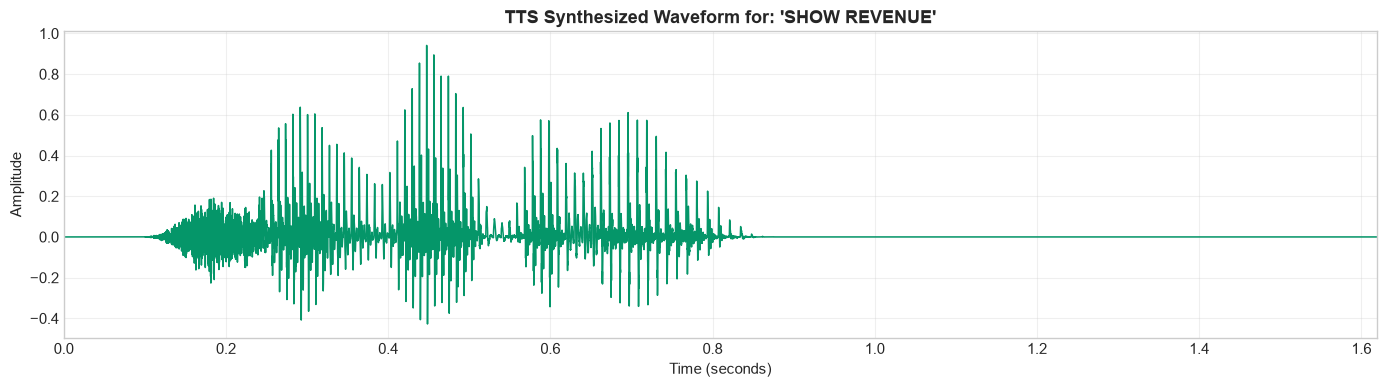

In [7]:
tts_wav_file = "synthesized_speech_output.wav"

try:
    engine = pyttsx3.init()
    engine.setProperty('rate', 150)
    engine.setProperty('volume', 1.0)
    engine.save_to_file(final_ctc_text, tts_wav_file)
    engine.runAndWait()
    tts_audio, tts_sr = sf.read(tts_wav_file)
except Exception:
    tts_sr = 16000
    t_synth = np.linspace(0, 1.8, int(tts_sr * 1.8))
    tts_audio = 0.5 * np.sin(2 * np.pi * 220 * t_synth) * np.exp(-t_synth)
    sf.write(tts_wav_file, tts_audio, tts_sr)

tts_time = np.linspace(0, len(tts_audio) / tts_sr, len(tts_audio))

fig, ax = plt.subplots(figsize=(14, 4))
ax.plot(tts_time, tts_audio, color='#059669', linewidth=1.1)
ax.set_title(f"TTS Synthesized Waveform for: '{final_ctc_text}'", fontsize=13, fontweight='bold')
ax.set_xlabel("Time (seconds)")
ax.set_ylabel("Amplitude")
ax.set_xlim(0, max(tts_time))
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

display(HTML("<b>▶️ Synthesized Speech Audio Playback:</b>"))
display(Audio(tts_audio, rate=tts_sr))
